<a href="https://colab.research.google.com/github/dishanth2k6/portfolio-optimization-monte-carlo/blob/main/Portfolio_Math_Engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import datetime as dt
tickers = ["AAPL","MSFT","GOOGL","AMZN"]
endDate=dt.datetime.now()
startDate=endDate-dt.timedelta(days=365*3)
prices=yf.download(tickers,startDate,endDate)
returns=prices["Close"].pct_change().dropna()
print(returns.head())

/tmp/ipykernel_3018/757763834.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices=yf.download(tickers,startDate,endDate)
[*********************100%***********************]  4 of 4 completed

Ticker          AAPL      AMZN     GOOGL      MSFT
Date                                              
2023-11-28  0.003214 -0.004738  0.005791  0.010803
2023-11-29 -0.005410 -0.004829 -0.016108 -0.010060
2023-11-30  0.003063 -0.001572 -0.018224  0.000158
2023-12-01  0.006791  0.006434 -0.005055 -0.011612
2023-12-04 -0.009465 -0.014895 -0.019642 -0.014339


In [ ]:
mean_returns=returns.mean()*252
print(mean_returns)
cov_matrix=returns.cov()*252
print(cov_matrix)

Ticker
AAPL     0.247934
AMZN     0.231895
GOOGL    0.291638
MSFT     0.135163
dtype: float64
Ticker      AAPL      AMZN     GOOGL      MSFT
Ticker                                        
AAPL    0.073143  0.031107  0.028751  0.024947
AMZN    0.031107  0.105205  0.058337  0.046748
GOOGL   0.028751  0.058337  0.099418  0.030197
MSFT    0.024947  0.046748  0.030197  0.071149


In [ ]:
def portfolio_stats(weights):
  dotProd=np.dot(weights,mean_returns)
  matmul=np.sqrt(np.dot(weights.T,np.dot(cov_matrix,weights)))
  return dotProd,matmul


In [ ]:
w = np.array([0.25, 0.25, 0.25, 0.25])
port_return , port_volatility = portfolio_stats(w)
print(f"Portfolio Return: {port_return:.6f}")
print(f"Portfolio Volatility (Std Dev): {port_volatility:.6f}")

Portfolio Return: 0.226657
Portfolio Volatility (Std Dev): 0.222077


In [ ]:
all_return=[]
all_volatility=[]
all_sharpe_ratio=[]
all_weights=[]
for i in range(5000):
  w=np.random.rand(4)
  w=w/np.sum(w)
  port_return,port_volatility=portfolio_stats(w)
  sharpe_ratio=port_return/port_volatility
  all_return.append(port_return)
  all_volatility.append(port_volatility)
  all_sharpe_ratio.append(sharpe_ratio)
  all_weights.append(w)
best_idx=np.argmax(all_sharpe_ratio)
print(all_sharpe_ratio[best_idx])
print(all_weights[best_idx])

1.1289325081592507
[0.48414666 0.06225877 0.41802816 0.0355664 ]


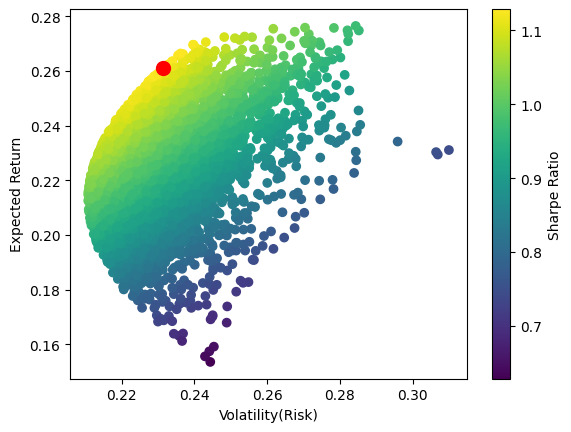

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(all_volatility,all_return,c=all_sharpe_ratio)
plt.colorbar(label="Sharpe Ratio")
plt.xlabel("Volatility(Risk)")
plt.ylabel("Expected Return")
plt.scatter(all_volatility[best_idx],all_return[best_idx],color='red',s=100)
plt.show()